# Urbane Luftverschmutzung: Cross Validation und Hyperparameter-Tuning (Gradient Boosting)

Dieses Notebook läuft **vor dem Feature Engineering**: Wir nehmen die Features
der Baseline aus Meilenstein 2 unverändert und prüfen, wie viel allein das
**Modell-Tuning** bringt. So lässt sich später sauber trennen, was vom
Tuning und was von den neuen Features kommt
(`lukas_feature_engineering.ipynb`).

**Ablauf**

1. Cross Validation mit Standardparametern als Referenz (Streuung zwischen den Folds ansehen).
2. Zufallssuche über einen Hyperparameter-Raum, bewertet per `GroupKFold` nach `Place_ID`.
3. **Verschachtelte Cross Validation** (Nested CV) als ehrliche Schätzung des getunten Modells.
4. Einfluss der Hyperparameter und Fehleranalyse.

**Wichtige Regeln**

- Train und Test enthalten **keine gemeinsamen Orte**, daher gruppiert jede Validierung nach `Place_ID`.
  Ein zufälliger Split würde Orte teilen und den Score zu optimistisch machen.
- Metrik ist RMSE (Vorgabe von Zindi), zusätzlich MAE und R².
- `target_min/max/variance/count` gibt es nur in Train (Leakage) und werden nicht verwendet.

In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("data")

## 1. Daten und Features (Baseline, unverändert)

In [2]:
train = pd.read_csv(DATA_DIR / "Train.csv", parse_dates=["Date"])

train["dayofyear"] = train["Date"].dt.day_of_year
train["weekday"] = train["Date"].dt.day_of_week
train["wind_speed"] = np.sqrt(train["u_component_of_wind_10m_above_ground"] ** 2
                              + train["v_component_of_wind_10m_above_ground"] ** 2)

features = [
    "wind_speed",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_CLOUD_cloud_fraction",
    "dayofyear",
    "weekday",
]
X, y, groups = train[features], train["target"], train["Place_ID"]
print(f"{len(features)} Features, {len(train)} Zeilen, {groups.nunique()} Orte")

8 Features, 30557 Zeilen, 340 Orte


## 2. Cross Validation mit Standardparametern

5-fach `GroupKFold`: Alle Zeilen eines Ortes liegen immer im Training **oder**
in der Validierung. Wir schauen neben dem Gesamtwert auch auf die Werte
je Fold, weil nur 340 Orte vorliegen und die Folds spürbar streuen.

In [3]:
outer_cv = GroupKFold(n_splits=5)
folds = list(outer_cv.split(X, y, groups))


def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


def cv_oof(params, cols=features):
    """Out-of-fold-Vorhersagen für eine Parameterkonfiguration."""
    oof = np.zeros(len(y))
    for tr, va in folds:
        m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **params)
        m.fit(X.iloc[tr][cols], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va][cols])
    return oof


def summarize(oof, name):
    fold = [rmse(y.iloc[va], oof[va]) for _, va in folds]
    return {"Modell": name, "RMSE": rmse(y, oof), "RMSE Fold-Std": np.std(fold),
            "RMSE Fold-Min": min(fold), "RMSE Fold-Max": max(fold),
            "MAE": mean_absolute_error(y, oof), "R²": r2_score(y, oof)}


oof_default = cv_oof({})
row_default = summarize(oof_default, "Standardparameter")
print("RMSE je Fold:", [round(rmse(y.iloc[va], oof_default[va]), 2) for _, va in folds])
pd.DataFrame([row_default]).set_index("Modell").round(2)

RMSE je Fold: [np.float64(33.66), np.float64(42.5), np.float64(36.01), np.float64(40.78), np.float64(30.73)]


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,37.0,4.38,30.73,42.5,26.17,0.38


## 3. Hyperparameter-Tuning (Zufallssuche)

Wir durchsuchen die wichtigsten Stellschrauben von `HistGradientBoostingRegressor`:

| Parameter | Bereich | Wirkung |
| --- | --- | --- |
| `learning_rate` | 0,01 bis 0,3 (log) | Schrittweite pro Baum |
| `max_iter` | 100 bis 600 | Anzahl Bäume |
| `max_leaf_nodes` | 8 bis 64 | Komplexität eines Baums |
| `max_depth` | 3, 5, 8, unbegrenzt | zusätzliche Tiefenbegrenzung |
| `min_samples_leaf` | 20 bis 400 | Mindestgröße eines Blatts (gegen Überanpassung) |
| `l2_regularization` | 0,001 bis 10 (log) | Strafe auf große Blattwerte |
| `max_features` | 0,5, 0,7, 1,0 | Anteil der Features pro Baum |

Die Zufallssuche (statt eines vollständigen Gitters) deckt einen großen Raum mit
wenigen Fits ab. Bewertet wird mit `GroupKFold` nach Orten, Ziel ist der RMSE.

In [4]:
param_space = {
    "learning_rate": loguniform(0.01, 0.3),
    "max_iter": randint(100, 600),
    "max_leaf_nodes": randint(8, 64),
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": randint(20, 400),
    "l2_regularization": loguniform(1e-3, 10),
    "max_features": [0.5, 0.7, 1.0],
}


def make_search(n_iter, cv):
    return RandomizedSearchCV(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        param_space, n_iter=n_iter, cv=cv,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE, n_jobs=1, refit=False)


t0 = time.time()
search = make_search(60, GroupKFold(n_splits=5))
search.fit(X, y, groups=groups)
print(f"Suche fertig in {time.time() - t0:.0f} s")

res = pd.DataFrame(search.cv_results_)
res["rmse"] = -res["mean_test_score"]
res = res.sort_values("rmse").reset_index(drop=True)
param_cols = [f"param_{p}" for p in param_space]
res[param_cols + ["rmse", "std_test_score"]].head(8).round(3)

Suche fertig in 253 s


,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_max_depth,param_min_samples_leaf,param_l2_regularization,param_max_features,rmse,std_test_score
0,0.063,316,52,None,60,0.976,0.7,36.653,4.356
1,0.094,599,56,5,21,0.011,0.5,36.696,4.421
2,0.108,503,31,None,73,0.013,1.0,36.733,4.426
3,0.078,128,43,8,32,0.004,1.0,36.741,4.363
4,0.089,555,43,8,123,1.317,0.5,36.744,4.356
5,0.087,548,42,8,120,0.829,1.0,36.777,4.377
6,0.020,576,25,None,237,0.050,0.7,36.787,4.450
7,0.036,546,29,5,70,0.022,1.0,36.809,4.461


Die besten Werte der Suche sind **optimistisch**: Wir haben aus 60 Konfigurationen
die beste gewählt, und genau auf diesen Folds bewertet. Wir prüfen sie daher
zuerst per Cross Validation gegen die Standardparameter und danach in der
verschachtelten Validierung (Abschnitt 4).

In [5]:
best_params = {p: res.loc[0, f"param_{p}"] for p in param_space}
# NumPy-Typen und None in normale Python-Werte umwandeln
best_params = {k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
               for k, v in best_params.items()}
for k in ("max_iter", "max_leaf_nodes", "min_samples_leaf"):
    best_params[k] = int(best_params[k])
print(json.dumps(best_params, indent=2))

oof_tuned = cv_oof(best_params)
row_tuned = summarize(oof_tuned, "Getunt (beste Konfiguration)")
print("RMSE je Fold (getunt):", [round(rmse(y.iloc[va], oof_tuned[va]), 2) for _, va in folds])
print("RMSE je Fold (Standard):", [round(rmse(y.iloc[va], oof_default[va]), 2) for _, va in folds])
pd.DataFrame([row_default, row_tuned]).set_index("Modell").round(2)

{
  "learning_rate": 0.06268891016222734,
  "max_iter": 316,
  "max_leaf_nodes": 52,
  "max_depth": null,
  "min_samples_leaf": 60,
  "l2_regularization": 0.9756194291174574,
  "max_features": 0.7
}


RMSE je Fold (getunt): [np.float64(33.5), np.float64(42.4), np.float64(35.83), np.float64(40.75), np.float64(30.79)]
RMSE je Fold (Standard): [np.float64(33.66), np.float64(42.5), np.float64(36.01), np.float64(40.78), np.float64(30.73)]


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,37.00,4.38,30.73,42.5,26.17,0.38
Getunt (beste Konfiguration),36.92,4.36,30.79,42.4,26.01,0.38


## 4. Verschachtelte Cross Validation (ehrliche Schätzung)

Im äußeren Loop (5 Folds) liegt ein Teil der Orte komplett zurück. Im inneren
Loop sucht eine Zufallssuche (25 Konfigurationen, 3-fach `GroupKFold`) nur auf
den Trainingsorten die beste Konfiguration. Das so gewählte Modell wird erst
dann auf den zurückgelegten Orten bewertet. Der Wert zeigt, was das **Verfahren
„Tuning“** auf unbekannten Orten leistet, ohne dass die Validierungsorte
bei der Wahl der Parameter mitgewirkt haben.

In [6]:
t0 = time.time()
oof_nested = np.zeros(len(y))
nested_params = []
for i, (tr, va) in enumerate(folds):
    inner = make_search(25, GroupKFold(n_splits=3))
    inner.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
    p = inner.cv_results_["params"][int(np.argmin(inner.cv_results_["rank_test_score"]))]
    nested_params.append(p)
    m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **p).fit(X.iloc[tr], y.iloc[tr])
    oof_nested[va] = m.predict(X.iloc[va])
    print(f"Fold {i + 1}/5: RMSE {rmse(y.iloc[va], oof_nested[va]):.2f} "
          f"(Standard: {rmse(y.iloc[va], oof_default[va]):.2f}), {time.time() - t0:.0f} s")

row_nested = summarize(oof_nested, "Getunt (verschachtelt)")
pd.DataFrame(nested_params).round(3)

Fold 1/5: RMSE 33.50 (Standard: 33.66), 58 s


Fold 2/5: RMSE 42.40 (Standard: 42.50), 114 s


Fold 3/5: RMSE 36.32 (Standard: 36.01), 167 s


Fold 4/5: RMSE 40.75 (Standard: 40.78), 218 s


Fold 5/5: RMSE 30.69 (Standard: 30.73), 276 s


,l2_regularization,learning_rate,max_depth,max_features,max_iter,max_leaf_nodes,min_samples_leaf
0,0.976,0.063,NaN,0.7,316,52,60
1,0.976,0.063,NaN,0.7,316,52,60
2,0.002,0.027,5.0,0.7,269,52,81
3,0.976,0.063,NaN,0.7,316,52,60
4,0.050,0.020,NaN,0.7,576,25,237


,RMSE,RMSE Fold-Std,RMSE Fold-Min,RMSE Fold-Max,MAE,R²
Modell,,,,,,
Standardparameter,37.00,4.38,30.73,42.5,26.17,0.38
Getunt (beste Konfiguration),36.92,4.36,30.79,42.4,26.01,0.38
Getunt (verschachtelt),37.00,4.37,30.69,42.4,26.12,0.38


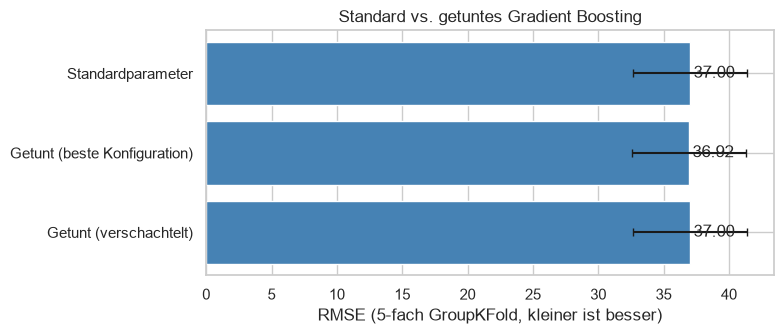

In [7]:
summary = pd.DataFrame([row_default, row_tuned, row_nested]).set_index("Modell")
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(summary.index[::-1], summary["RMSE"][::-1], color="steelblue",
        xerr=summary["RMSE Fold-Std"][::-1], capsize=3)
for i, v in enumerate(summary["RMSE"][::-1]):
    ax.text(v + 0.3, i, f"{v:.2f}", va="center")
ax.set_xlabel("RMSE (5-fach GroupKFold, kleiner ist besser)")
ax.set_title("Standard vs. getuntes Gradient Boosting")
plt.tight_layout()
plt.show()

## 5. Einfluss der Hyperparameter

Welche Parameter bestimmen den Score? Jeder Punkt ist eine der 60 Konfigurationen
der Zufallssuche (RMSE aus 5-fach `GroupKFold`).

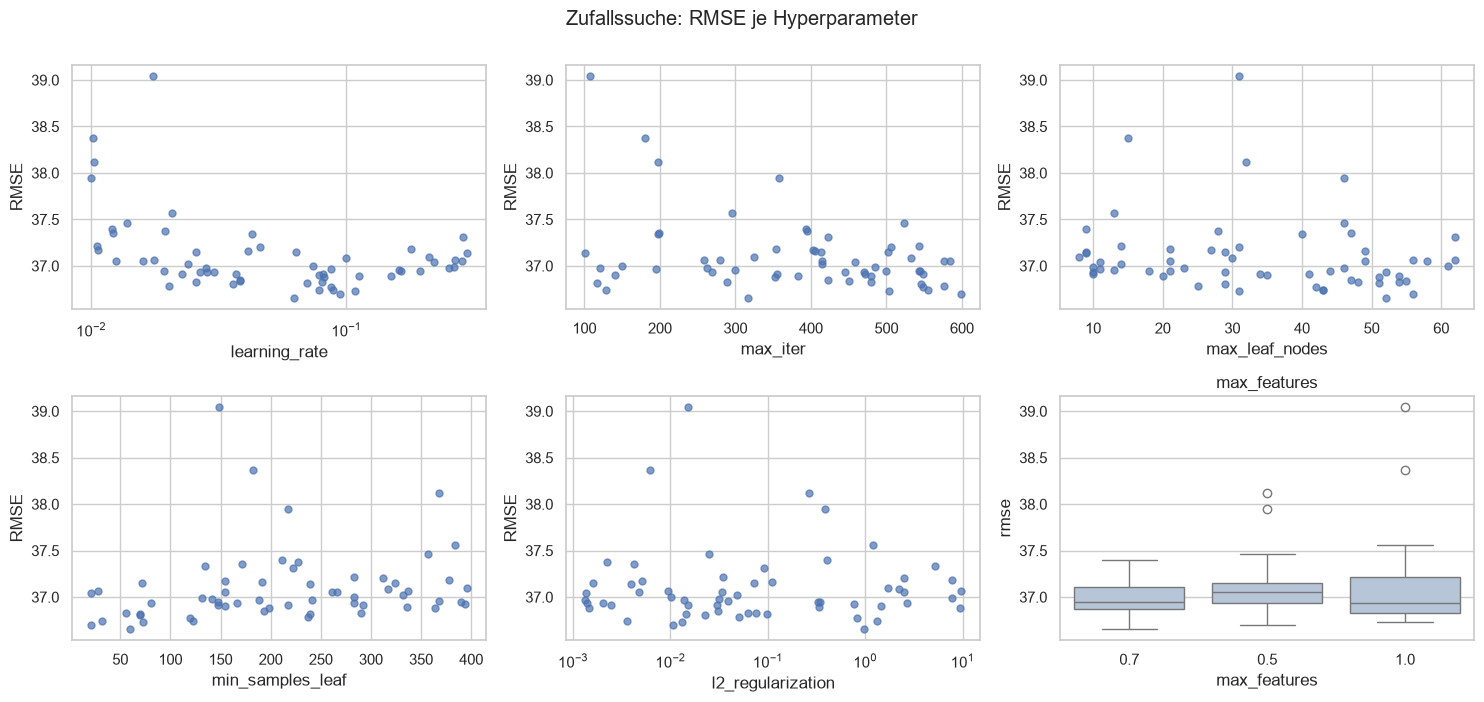

Spearman-Korrelation mit RMSE:
param_max_iter            -0.27
param_max_leaf_nodes      -0.26
param_min_samples_leaf     0.34
param_l2_regularization    0.05
log_lr                    -0.35


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
plots = [("learning_rate", True), ("max_iter", False), ("max_leaf_nodes", False),
         ("min_samples_leaf", False), ("l2_regularization", True)]
for ax, (p, log) in zip(axes.ravel(), plots):
    ax.scatter(res[f"param_{p}"].astype(float), res["rmse"], s=25, alpha=0.7)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(p); ax.set_ylabel("RMSE")
cat = res.assign(max_depth=res["param_max_depth"].astype(str),
                 max_features=res["param_max_features"].astype(str))
sns.boxplot(data=cat, x="max_features", y="rmse", ax=axes[1, 2], color="lightsteelblue")
axes[1, 2].set_title("max_features")
plt.suptitle("Zufallssuche: RMSE je Hyperparameter", y=1.0)
plt.tight_layout()
plt.show()

num = res[["rmse"] + [f"param_{p}" for p in ["learning_rate", "max_iter", "max_leaf_nodes",
                                              "min_samples_leaf", "l2_regularization"]]].astype(float)
num["log_lr"] = np.log(num["param_learning_rate"])
print("Spearman-Korrelation mit RMSE:")
print(num.drop(columns="param_learning_rate").corr(method="spearman")["rmse"].drop("rmse").round(2).to_string())

## 6. Fehleranalyse: Standard vs. getunt

Wo verbessert das Tuning die Vorhersage, und bleibt das Spitzenwert-Problem
bestehen?

,Zeilen,MAE_Standard,MAE_Getunt,Anteil Fehler Getunt
bin,,,,
"(0, 25]",7718,25.08,24.67,0.17
"(25, 50]",7635,17.86,17.80,0.11
"(50, 100]",10265,18.82,19.06,0.15
"(100, 150]",2627,41.89,41.43,0.14
"(150, 200]",2056,64.72,63.46,0.26
"(200, 1000]",256,131.08,131.14,0.18


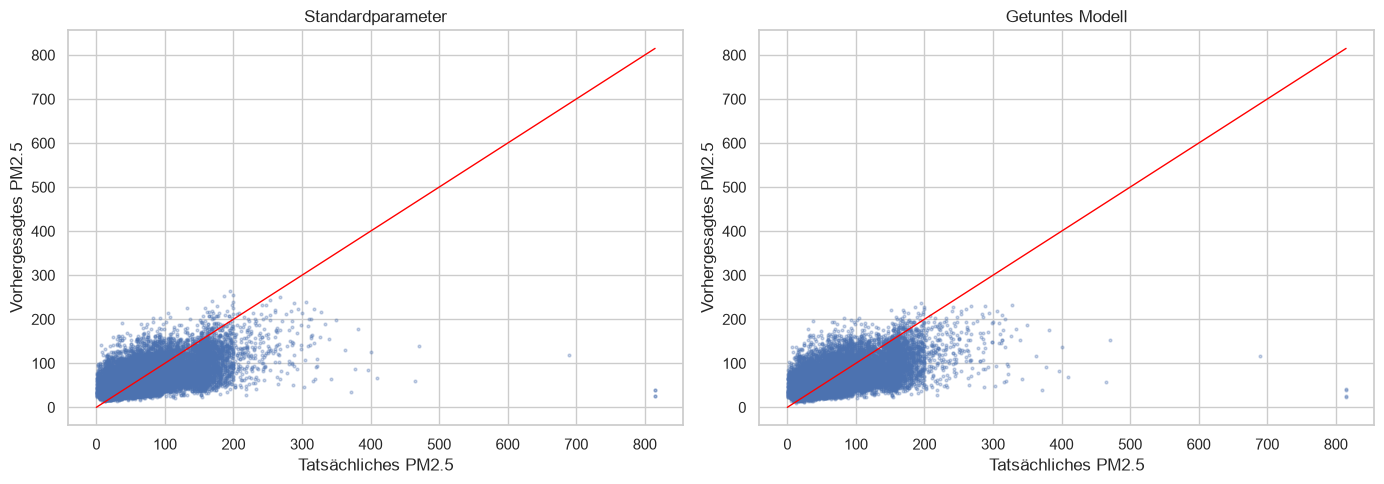

Gespeichert: models/gb_best_params_baseline_features.json


In [9]:
bins = pd.cut(y, [0, 25, 50, 100, 150, 200, 1000])
err = pd.DataFrame({"bin": bins,
                    "MAE_Standard": np.abs(y - oof_default),
                    "MAE_Getunt": np.abs(y - oof_tuned),
                    "se_std": (y - oof_default) ** 2, "se_tuned": (y - oof_tuned) ** 2})
by_bin = err.groupby("bin", observed=True).agg(
    Zeilen=("MAE_Standard", "size"), MAE_Standard=("MAE_Standard", "mean"),
    MAE_Getunt=("MAE_Getunt", "mean"), SE_Std=("se_std", "sum"), SE_Tuned=("se_tuned", "sum"))
by_bin["Anteil Fehler Getunt"] = (by_bin["SE_Tuned"] / by_bin["SE_Tuned"].sum()).round(3)
display(by_bin.drop(columns=["SE_Std", "SE_Tuned"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, pred, title in zip(axes, [oof_default, oof_tuned], ["Standardparameter", "Getuntes Modell"]):
    ax.scatter(y, pred, s=4, alpha=0.3)
    lim = [0, max(y.max(), pred.max())]
    ax.plot(lim, lim, color="red", lw=1)
    ax.set_xlabel("Tatsächliches PM2.5"); ax.set_ylabel("Vorhergesagtes PM2.5")
    ax.set_title(title)
plt.tight_layout()
plt.show()

Path("models").mkdir(exist_ok=True)
with open("models/gb_best_params_baseline_features.json", "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=2)
print("Gespeichert: models/gb_best_params_baseline_features.json")

## 7. Ergebnis und Einordnung

**RMSE (5-fach GroupKFold nach Ort, 8 Baseline-Features)**

| Modell | RMSE | Fold-Std | MAE | R² |
| --- | --- | --- | --- | --- |
| Standardparameter | 37,00 | 4,38 | 26,17 | 0,38 |
| Getunt, beste Konfiguration (optimistisch) | 36,92 | 4,36 | 26,01 | 0,38 |
| Getunt, verschachtelt (ehrlich) | 37,00 | 4,37 | 26,12 | 0,38 |

**Beobachtungen**

- **Tuning bringt auf diesen Features praktisch nichts.** Die beste von 60
  Konfigurationen verbessert den RMSE nur um 0,08. In der verschachtelten
  Validierung bleibt die Verbesserung bei 0,00. Der Unterschied liegt weit unter
  der Streuung zwischen den Folds (etwa 4).
- **Die Folds streuen stark** (RMSE 30,7 bis 42,5). Bei nur 340 Orten hängt der Score
  davon ab, welche Orte in der Validierung landen. Kleine Unterschiede zwischen
  Modellen sind deshalb nicht belastbar, solange sie nicht über alle Folds
  gleichgerichtet auftreten.
- **Die Suche ist flach:** Die besten acht Konfigurationen liegen zwischen 36,65
  und 36,81. Tendenz: kleinere Lernrate, mehr Bäume und größere Blätter
  (`min_samples_leaf`) sind etwas besser. Die Korrelationen mit dem RMSE
  liegen bei höchstens 0,35 in beide Richtungen.
- **Spitzenwerte bleiben das Problem:** Der MAE bei Werten über 200 ändert sich
  nicht (131,1 gegen 131,1). Werte über 150 verursachen weiterhin etwa 44 % des
  quadratischen Fehlers.
- **Die gewählten Parameter in der verschachtelten Validierung** wechseln je Fold.
  Das bestätigt, dass die Landschaft flach ist und keine Konfiguration klar gewinnt.

**Schlussfolgerung**

Der Engpass liegt bei den **Features**, nicht bei den Modelleinstellungen. Mit den
8 Baseline-Features erreicht auch ein sorgfältig getuntes Modell nur 37,0.
Die Orts-Aggregate in `lukas_feature_engineering.ipynb` senken den RMSE dagegen
auf rund 30. Tuning lohnt sich erst wieder auf dem verbesserten Feature-Set, und
dann sollte der Suchraum um stärkere Regularisierung und das Spitzenwert-Problem
ergänzt werden (z. B. `log1p(target)`).

Die beste Konfiguration liegt in `models/gb_best_params_baseline_features.json`.
Sie ist kein klarer Gewinner und dient nur als Ausgangspunkt für spätere Suchen.
